In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib

from scipy.stats import mannwhitneyu, chi2_contingency
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

sns.set_theme(style="whitegrid")

df = pd.read_csv("IMDB Dataset.csv  ")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [2]:
import re

# Check missing values and duplicates
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate reviews:", df["review"].duplicated().sum())

# Remove missing values
df = df.dropna(subset=["review", "sentiment"]).copy()

# Standardize sentiment labels
df["sentiment"] = df["sentiment"].astype(str).str.lower().str.strip()

# Keep only positive and negative reviews
df = df[df["sentiment"].isin(["positive", "negative"])].copy()

# Remove duplicate reviews
df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)

# Clean review text
def clean_review(text):
    text = str(text)
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["review"] = df["review"].apply(clean_review)

# Convert sentiment into numerical labels
df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

# Create features for EDA
df["word_count"] = df["review"].apply(lambda x: len(x.split()))
df["char_count"] = df["review"].str.len()

print("\nCleaned dataset shape:", df.shape)
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

display(df.head())

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate reviews: 418

Cleaned dataset shape: (49582, 5)

Sentiment distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


,review,sentiment,label,word_count,char_count
0,One of the other reviewers has mentioned that ...,positive,1,304,1728
1,A wonderful little production. The filming tec...,positive,1,156,962
2,I thought this was a wonderful way to spend ti...,positive,1,164,904
3,Basically there's a family where a little boy ...,negative,0,135,715
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1,225,1272


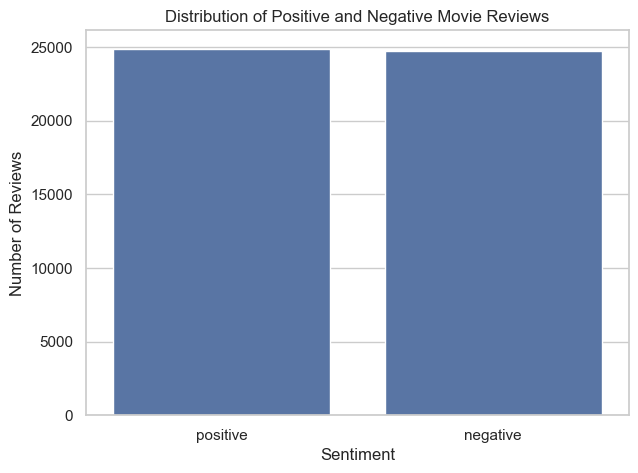

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="sentiment")

plt.title("Distribution of Positive and Negative Movie Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


In [ ]:
# Descriptive statistics for reviewing length.



print("Review length statistics by sentiment:\n")

display(
    df.groupby("sentiment")[["word_count", "char_count"]]
      .agg(["mean", "median", "std", "min", "max"])
      .round(2)
)


Review length statistics by sentiment:



word_count                          char_count                      \
                mean median     std min   max       mean median      std min   
sentiment                                                                      
negative      227.24  173.0  163.34   4  1491    1271.55  958.0   929.00  32   
positive      230.86  171.0  175.94  10  2459    1304.42  953.0  1015.45  65   

                  
             max  
sentiment         
negative    8698  
positive   13593

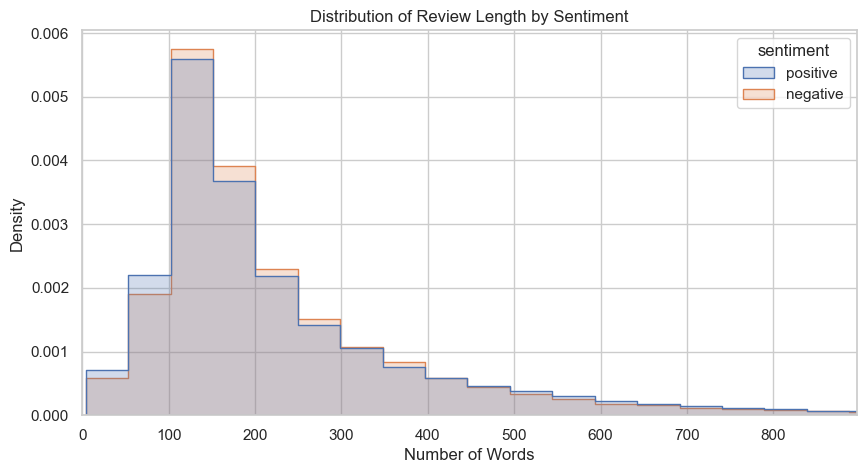

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue="sentiment",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlim(0, df["word_count"].quantile(0.99))
plt.title("Distribution of Review Length by Sentiment")
plt.xlabel("Number of Words")
plt.ylabel("Density")
plt.show()


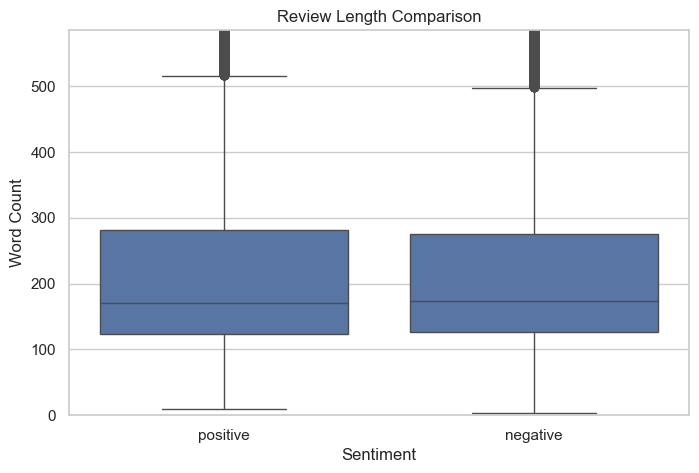

In [6]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sentiment",
    y="word_count"
)

plt.ylim(0, df["word_count"].quantile(0.95))
plt.title("Review Length Comparison")
plt.xlabel("Sentiment")
plt.ylabel("Word Count")
plt.show()


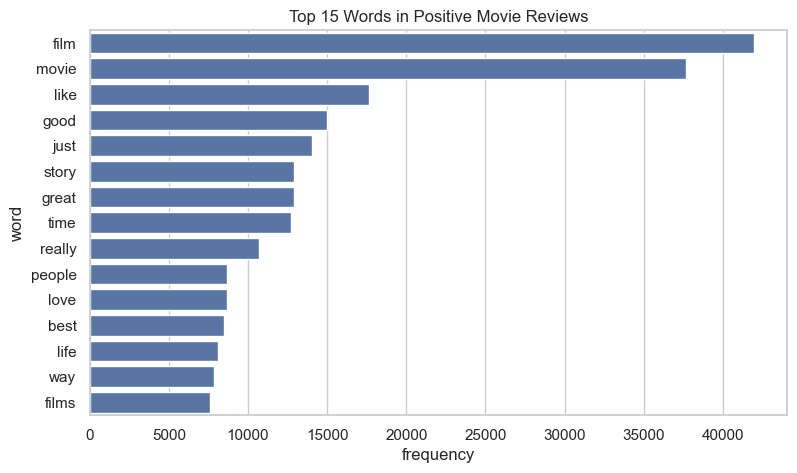

In [7]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def get_top_words(texts, n=15):
    words = []

    for text in texts:
        tokens = re.findall(r"\b[a-zA-Z]{3,}\b", text.lower())
        words.extend(
            word for word in tokens
            if word not in ENGLISH_STOP_WORDS
        )

    return Counter(words).most_common(n)

positive_words = get_top_words(
    df.loc[df["sentiment"] == "positive", "review"]
)

positive_df = pd.DataFrame(
    positive_words, columns=["word", "frequency"]
)

plt.figure(figsize=(9, 5))
sns.barplot(data=positive_df, x="frequency", y="word")
plt.title("Top 15 Words in Positive Movie Reviews")
plt.show()


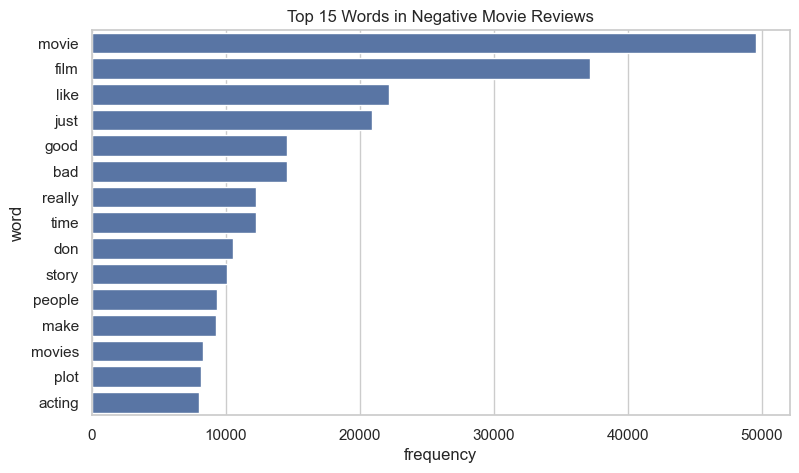

In [8]:
negative_words = get_top_words(
    df.loc[df["sentiment"] == "negative", "review"]
)

negative_df = pd.DataFrame(
    negative_words, columns=["word", "frequency"]
)

plt.figure(figsize=(9, 5))
sns.barplot(data=negative_df, x="frequency", y="word")
plt.title("Top 15 Words in Negative Movie Reviews")
plt.show()

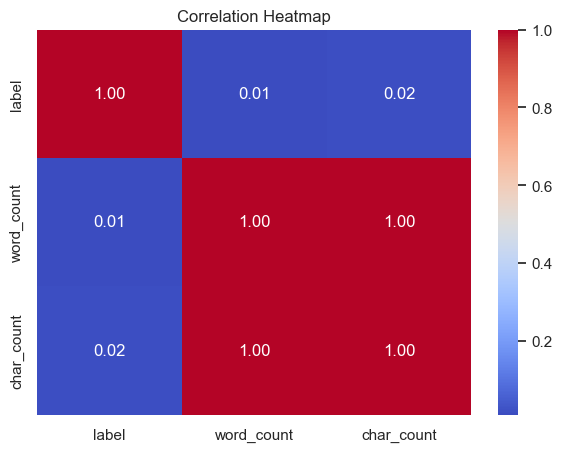

            label  word_count  char_count
label       1.000       0.011       0.017
word_count  0.011       1.000       0.997
char_count  0.017       0.997       1.000


In [9]:
plt.figure(figsize=(7, 5))

correlation = df[
    ["label", "word_count", "char_count"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

print(correlation.round(3))



In [10]:
print("Overall descriptive statistics:")

display(
    df[["word_count", "char_count"]]
    .describe()
    .round(2)
)

print("\nStatistics by sentiment:")

display(
    df.groupby("sentiment")[["word_count", "char_count"]]
    .agg(["mean", "median", "std"])
    .round(2)
)




Overall descriptive statistics:


,word_count,char_count
count,49582.00,49582.00
mean,229.06,1288.04
std,169.79,973.48
min,4.00,32.00
25%,125.00,690.00
50%,172.00,956.00
75%,278.00,1562.00
max,2459.00,13593.00



Statistics by sentiment:


word_count                char_count                
                mean median     std       mean median      std
sentiment                                                     
negative      227.24  173.0  163.34    1271.55  958.0   929.00
positive      230.86  171.0  175.94    1304.42  953.0  1015.45

In [11]:
from scipy.stats import mannwhitneyu

positive_lengths = df.loc[
    df["sentiment"] == "positive", "word_count"
]

negative_lengths = df.loc[
    df["sentiment"] == "negative", "word_count"
]

statistic, p_value = mannwhitneyu(
    positive_lengths,
    negative_lengths,
    alternative="two-sided"
)

print("Mann–Whitney U statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Review lengths differ significantly by sentiment.")
else:
    print("Conclusion: No statistically significant difference was detected.")



Mann–Whitney U statistic: 304154199.0
P-value: 0.048907603563092886
Conclusion: Review lengths differ significantly by sentiment.


In [12]:
from scipy.stats import chi2_contingency

df["length_group"] = pd.cut(
    df["word_count"],
    bins=[-1, 100, 200, 500, float("inf")],
    labels=["0-100", "101-200", "201-500", "500+"]
)

contingency_table = pd.crosstab(
    df["length_group"],
    df["sentiment"]
)

display(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Review-length category is associated with sentiment.")
else:
    print("Conclusion: No statistically significant association was detected.")





sentiment,negative,positive
length_group,,
0-100,2873,3397
101-200,11852,11456
201-500,8237,7977
500+,1736,2054


Chi-square statistic: 80.67442865659842
Degrees of freedom: 3
P-value: 2.1997078970378536e-17
Conclusion: Review-length category is associated with sentiment.


In [13]:
from sklearn.model_selection import train_test_split

X = df["review"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining sentiment distribution:")
print(y_train.value_counts())


Training samples: 39665
Testing samples: 9917

Training sentiment distribution:
label
1    19907
0    19758
Name: count, dtype: int64


In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Create baseline model
baseline = DummyClassifier(strategy="most_frequent")

# Train baseline
baseline.fit(
    np.zeros((len(y_train), 1)),
    y_train
)

# Predict on test data
baseline_predictions = baseline.predict(
    np.zeros((len(y_test), 1))
)

# Evaluate baseline
print("Baseline Accuracy:",
      round(accuracy_score(y_test, baseline_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    target_names=["Negative", "Positive"],
    zero_division=0
))


Baseline Accuracy: 0.5019

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00      4940
    Positive       0.50      1.00      0.67      4977

    accuracy                           0.50      9917
   macro avg       0.25      0.50      0.33      9917
weighted avg       0.25      0.50      0.34      9917



In [15]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

models = {
    "Naive Bayes": (
        MultinomialNB(),
        {
            "tfidf__min_df": [2, 5],
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "classifier__alpha": [0.5, 1.0]
        }
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=1500, random_state=42),
        {
            "tfidf__min_df": [2, 5],
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "classifier__C": [0.5, 1.0, 2.0]
        }
    ),
    "Linear SVM": (
        LinearSVC(random_state=42),
        {
            "tfidf__min_df": [2, 5],
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "classifier__C": [0.5, 1.0, 2.0]
        }
    )
}

best_models = {}
cv_results = []

for name, (classifier, params) in models.items():
    print(f"\nTraining and tuning: {name}")

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english",
            max_features=50000,
            sublinear_tf=True
        )),
        ("classifier", classifier)
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        scoring="f1",
        cv=3,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    cv_results.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print("Best CV F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

cv_df = pd.DataFrame(cv_results)
display(cv_df)



Training and tuning: Naive Bayes
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV F1: 0.8763
Best parameters: {'classifier__alpha': 0.5, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}

Training and tuning: Logistic Regression
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best CV F1: 0.8989
Best parameters: {'classifier__C': 2.0, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2)}

Training and tuning: Linear SVM
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best CV F1: 0.9004
Best parameters: {'classifier__C': 0.5, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}


,Model,Best CV F1,Best Parameters
0,Naive Bayes,0.876327,"{'classifier__alpha': 0.5, 'tfidf__min_df': 2,..."
1,Logistic Regression,0.898940,"{'classifier__C': 2.0, 'tfidf__min_df': 5, 'tf..."
2,Linear SVM,0.900360,"{'classifier__C': 0.5, 'tfidf__min_df': 2, 'tf..."


In [16]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

results = []
test_predictions = {}
test_scores = {}

for name, model in best_models.items():
    pred = model.predict(X_test)
    test_predictions[name] = pred

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)

    test_scores[name] = scores

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Linear SVM,0.9039,0.8967,0.9138,0.9052,0.9664
1,Logistic Regression,0.9027,0.8960,0.9120,0.9039,0.9667
2,Naive Bayes,0.8799,0.8738,0.8891,0.8814,0.9480



Model: Naive Bayes
              precision    recall  f1-score   support

    Negative       0.89      0.87      0.88      4940
    Positive       0.87      0.89      0.88      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917



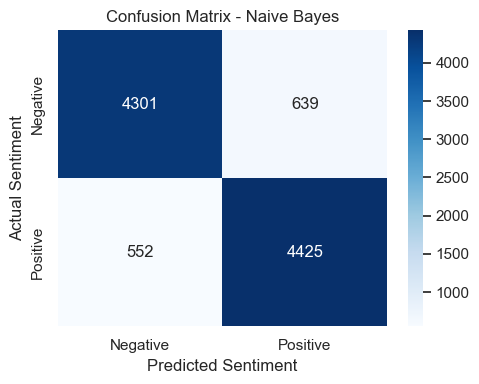


Model: Logistic Regression
              precision    recall  f1-score   support

    Negative       0.91      0.89      0.90      4940
    Positive       0.90      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



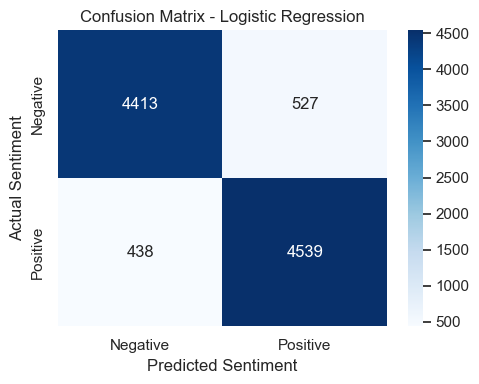


Model: Linear SVM
              precision    recall  f1-score   support

    Negative       0.91      0.89      0.90      4940
    Positive       0.90      0.91      0.91      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



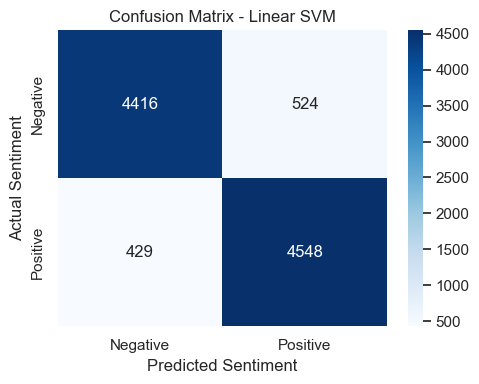

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

for name, pred in test_predictions.items():
    print(f"\n{'='*50}")
    print(f"Model: {name}")
    print(classification_report(
        y_test,
        pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"]
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")
    plt.tight_layout()
    plt.show()

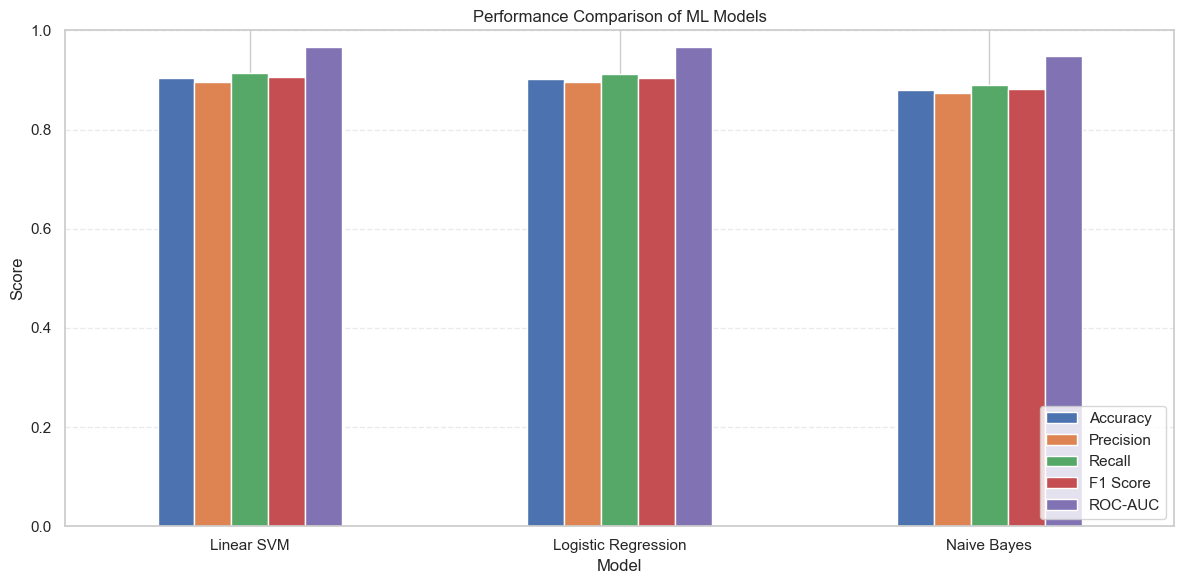

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# 1. Compare model performance
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

results_df.set_index("Model")[metrics].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1), rot=0
)

plt.title("Performance Comparison of ML Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

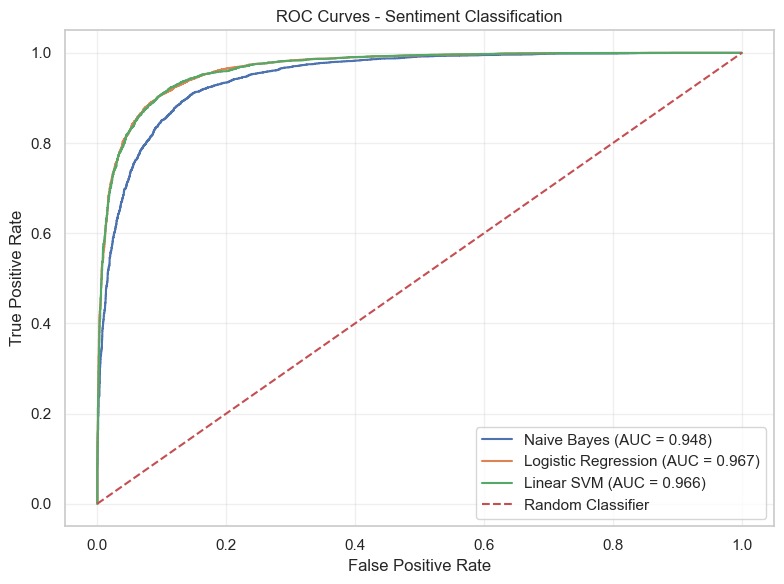

In [ ]:
# 2. ROC curves
plt.figure(figsize=(8, 6))

for name, scores in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Sentiment Classification")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Top Positive Sentiment Features:


,Word,Coefficient
14081,excellent,9.615300
19142,great,8.504648
33432,perfect,7.817918
1782,amazing,7.482818
4022,best,7.335075
49093,wonderful,6.876274
5335,brilliant,6.250814
14960,favorite,6.213565
26948,loved,5.981132
20714,hilarious,5.862310


Top Negative Sentiment Features:


,Word,Coefficient
49363,worst,-13.772878
3040,awful,-11.168582
4992,boring,-9.841051
47966,waste,-9.107092
3143,bad,-8.626909
34515,poor,-8.551843
44162,terrible,-8.451700
12549,dull,-7.334545
21134,horrible,-7.059520
49346,worse,-7.057045


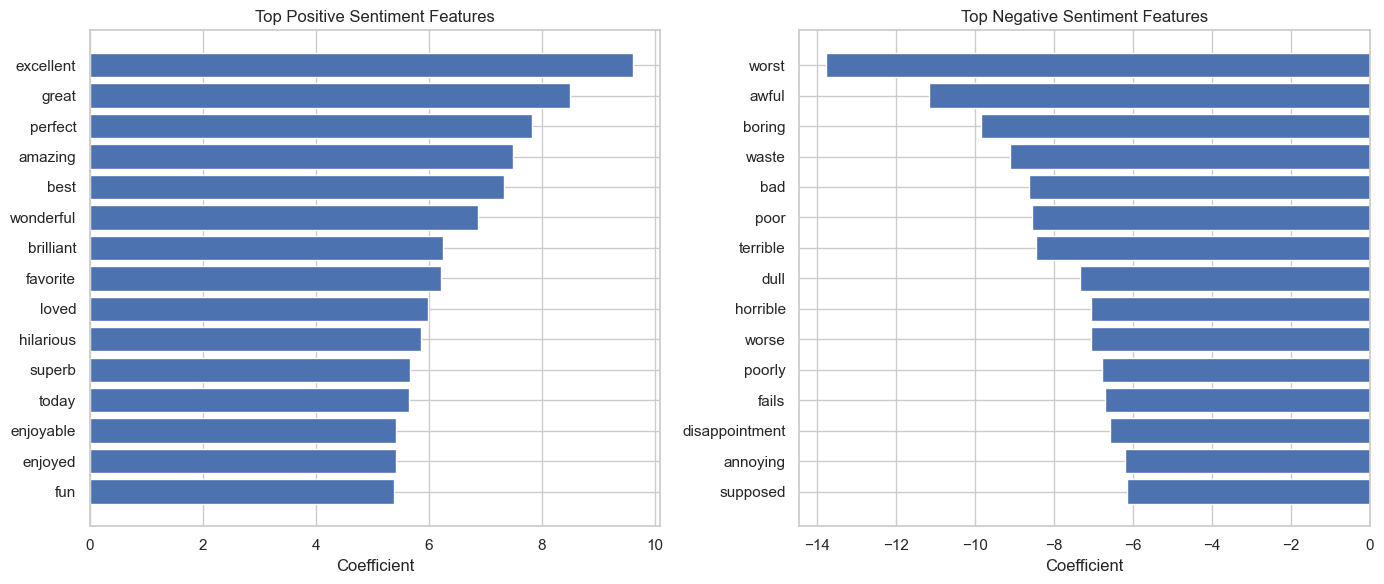

In [19]:

import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Logistic Regression model
lr_model = best_models["Logistic Regression"]

# Extract TF-IDF vectorizer and classifier
vectorizer = lr_model.named_steps["tfidf"]
classifier = lr_model.named_steps["classifier"]

feature_names = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]

# Top positive and negative sentiment words
feature_df = pd.DataFrame({
    "Word": feature_names,
    "Coefficient": coefficients
})

top_positive = feature_df.nlargest(15, "Coefficient")
top_negative = feature_df.nsmallest(15, "Coefficient")

print("Top Positive Sentiment Features:")
display(top_positive)

print("Top Negative Sentiment Features:")
display(top_negative)

# Visualize important features
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(
    top_positive["Word"][::-1],
    top_positive["Coefficient"][::-1]
)
axes[0].set_title("Top Positive Sentiment Features")
axes[0].set_xlabel("Coefficient")

axes[1].barh(
    top_negative["Word"][::-1],
    top_negative["Coefficient"][::-1]
)
axes[1].set_title("Top Negative Sentiment Features")
axes[1].set_xlabel("Coefficient")

plt.tight_layout()
plt.show()

